In [1]:
#Copiare sempre qui la query dello step0 -> poi usare array con i family_id per le analisi successive 
from pathlib import Path
import pandas as pd
from sqlalchemy import and_, func, or_

from epo.tipdata.patstat import PatstatClient
from epo.tipdata.patstat.database.models import (
    TLS201_APPLN,
    TLS202_APPLN_TITLE,
    TLS203_APPLN_ABSTR,
    TLS224_APPLN_CPC,
)

ENV = "PROD"  # per il risultato finale rilanciare con "PROD"
OUTPUT_DIR = Path("outputs/step0")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

patstat = PatstatClient(env=ENV)
db = patstat.orm()

SECTOR_NAME = "Quantum Computing"

# Classi CPC "core": prefisso senza spazi
SECTOR_CPC_PREFIXES = (
    "G06N10/",      # Quantum computing (dal 2019), include /20 /40 /60 /70 /80
    "G06N99/002",   # Quantum computers (collocazione storica, pre-2019)
    "Y10S977/933",  # Spintronics or quantum computing (collezione storica)
)

# Classi CPC "adiacenti": valide solo se accompagnate da testo quantistico
ADJACENT_CPC_PREFIXES = (
    "B82Y10/00",    # Nanotecnologie per elaborazione dell'informazione
    "H10N60/",      # Dispositivi superconduttori
    "H01L39/",      # Dispositivi superconduttori (vecchia collocazione)
    "H03K19/195",   # Logica superconduttiva
)

SECTOR_KEYWORDS = (
    "quantum comput",   # computer, computing, computation
    "qubit",
    "quantum bit",
    "quantum processor",
    "quantum gate",
    "quantum circuit",
    "quantum annealing",
    "quantum error correction",
    "quantum algorithm",
    "quantum simulator",
)

# Keyword generiche: usate SOLO in AND con le classi CPC adiacenti
ADJACENT_KEYWORDS = ("quantum", "josephson")

START_YEAR = 2010   # anno di primo deposito della famiglia
END_YEAR = 2023

IPR_TYPE = "PI"  # "PI" = Patented Inventions (esclude i modelli di utilità)


def symbol_prefix_condition(symbol_column, codes):
    symbol = func.replace(symbol_column, " ", "")
    return or_(*(symbol.like(code.replace(" ", "") + "%") for code in codes))


def keyword_condition(terms):
    title = func.lower(func.coalesce(TLS202_APPLN_TITLE.appln_title, ""))
    abstract = func.lower(func.coalesce(TLS203_APPLN_ABSTR.appln_abstract, ""))
    return or_(*(col.like(f"%{t.lower()}%") for t in terms for col in (title, abstract)))


def sector_family_ids():
    family_id = TLS201_APPLN.docdb_family_id.label("docdb_family_id")

    def base():
        return (
            db.query(family_id)
            .select_from(TLS201_APPLN)
            .filter(TLS201_APPLN.docdb_family_id > 0)  # esclude domande senza famiglia
            .filter(TLS201_APPLN.earliest_filing_year.between(START_YEAR, END_YEAR))
            .filter(TLS201_APPLN.ipr_type == IPR_TYPE) 
        )

    def join_cpc(q):
        return q.join(TLS224_APPLN_CPC, TLS201_APPLN.appln_id == TLS224_APPLN_CPC.appln_id)

    def join_text(q):
        return (
            q.outerjoin(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
            .outerjoin(TLS203_APPLN_ABSTR, TLS201_APPLN.appln_id == TLS203_APPLN_ABSTR.appln_id)
        )

    # Perimetro CPC core
    by_cpc = join_cpc(base()).filter(
        symbol_prefix_condition(TLS224_APPLN_CPC.cpc_class_symbol, SECTOR_CPC_PREFIXES)
    )

    # Perimetro keyword specifiche
    by_keywords = join_text(base()).filter(keyword_condition(SECTOR_KEYWORDS))

    # CPC adiacente AND keyword generica
    by_adjacent = join_text(join_cpc(base())).filter(
        and_(
            symbol_prefix_condition(TLS224_APPLN_CPC.cpc_class_symbol, ADJACENT_CPC_PREFIXES),
            keyword_condition(ADJACENT_KEYWORDS),
        )
    )

    return by_cpc.union(by_keywords).union(by_adjacent)


family_ids = sector_family_ids()

In [2]:
# Converti la query in una lista di ID 
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

family_ids = [row.docdb_family_id for row in family_ids.all()]

Total family and patents

In [3]:
# 1 & 2: Numero totale di family e di application (patent) nel settore
total_families = len(family_ids)

n_applications = func.count(TLS201_APPLN.appln_id)
total_patents = db.query(n_applications).filter(
    TLS201_APPLN.docdb_family_id.in_(family_ids),
    TLS201_APPLN.ipr_type == IPR_TYPE
).scalar()

print(f"Numero di family (invenzioni): {total_families:,}")
print(f"Numero di applications (brevetti): {total_patents:,}")


Numero di family (invenzioni): 11,571
Numero di applications (brevetti): 26,075


Applicants for each family

In [4]:
# Calcola il numero di brevetti (applications) per ciascuna family del settore
n_applications = func.count(TLS201_APPLN.appln_id)

family_size_query = (
    db.query(
        TLS201_APPLN.docdb_family_id,
        n_applications.label("n_patents")
    )
    .filter(
        TLS201_APPLN.docdb_family_id.in_(family_ids),
        TLS201_APPLN.ipr_type == IPR_TYPE
    )
    .group_by(TLS201_APPLN.docdb_family_id)
)

# Trasforma il risultato della query in un DataFrame di Pandas
df_family_size = patstat.df(family_size_query)

# Mostra le prime righe per verificare che sia corretto
display(df_family_size.head())

,docdb_family_id,n_patents
0,68241829,11
1,96022630,2
2,80934030,4
3,57234694,4
4,72900132,1


In [5]:
# Calcola la distribuzione
df_counts = df_family_size["n_patents"].value_counts().reset_index()
df_counts.columns = ["n_patents_in_family", "n_families"]
df_counts = df_counts.sort_values("n_patents_in_family").reset_index(drop=True)

# Crea la tabella finale con la riga dei Totali
df_table = df_counts.copy()
total_row = pd.DataFrame({
    "n_patents_in_family": ["TOTALE"],
    "n_families": [df_table["n_families"].sum()]
})
df_table = pd.concat([df_table, total_row], ignore_index=True)

print("Distribuzione delle Family in base al numero di brevetti:")
print(df_table.to_string(index=False))


Distribuzione delle Family in base al numero di brevetti:
n_patents_in_family  n_families
                  1        6808
                  2        1645
                  3        1034
                  4         693
                  5         414
                  6         311
                  7         259
                  8         135
                  9          81
                 10          58
                 11          34
                 12          29
                 13          23
                 14          10
                 15           7
                 16           7
                 17           5
                 18           2
                 19           3
                 20           3
                 23           2
                 24           2
                 26           1
                 31           1
                 41           1
                 46           1
                 48           1
                 63           1
             T

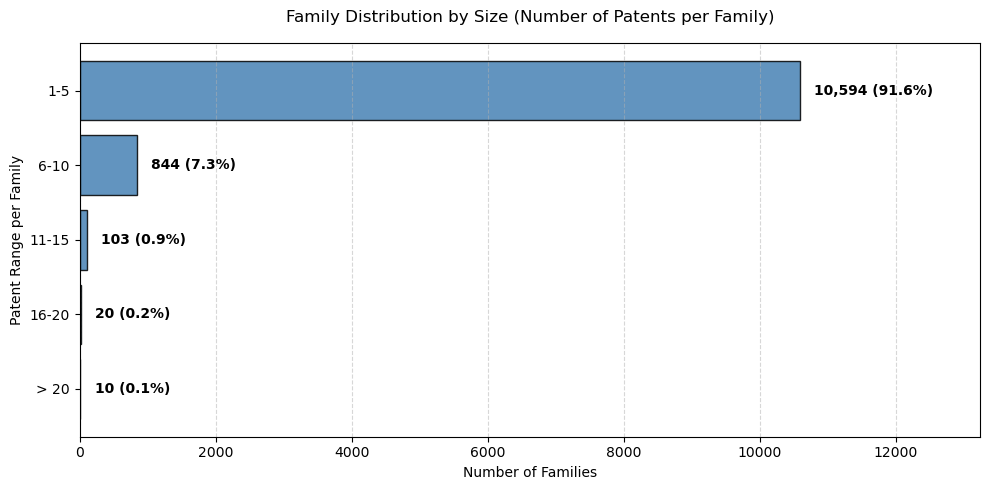

In [6]:
# Calcoliamo i bucket
bins = [0, 5, 10, 15, 20, np.inf]
labels = ["1-5", "6-10", "11-15", "16-20", "> 20"]

df_family_size["bucket"] = pd.cut(
    df_family_size["n_patents"], 
    bins=bins, 
    labels=labels, 
    right=True
)

df_buckets = df_family_size["bucket"].value_counts().reindex(labels).reset_index()
df_buckets.columns = ["bucket", "n_families"]
df_buckets["percentage"] = (df_buckets["n_families"] / df_buckets["n_families"].sum()) * 100

# Grafico a barre orizzontali con etichette in inglese
fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(df_buckets["bucket"], df_buckets["n_families"], color="steelblue", edgecolor="black", alpha=0.85)

# Aggiungiamo i valori e le percentuali vicino alle barre
for bar in bars:
    width = bar.get_width()
    pct = (width / df_buckets["n_families"].sum()) * 100
    ax.text(width + (df_buckets["n_families"].max() * 0.02), bar.get_y() + bar.get_height()/2, 
            f"{width:,} ({pct:.1f}%)", 
            va='center', ha='left', fontsize=10, fontweight='bold')

ax.set_title("Family Distribution by Size (Number of Patents per Family)", fontsize=12, pad=15)
ax.set_xlabel("Number of Families", fontsize=10)
ax.set_ylabel("Patent Range per Family", fontsize=10)
ax.grid(axis="x", linestyle="--", alpha=0.5)

# Estendiamo leggermente l'asse x per fare spazio alle etichette
ax.set_xlim(0, df_buckets["n_families"].max() * 1.25)

plt.gca().invert_yaxis() # Mette la fascia "1-5" in alto
plt.tight_layout()
plt.show()

Granted applican
COME CONSIDERARE PER FAMILY? TENGO QUELLE CHE HANNO ALMENO 1 APPLICAN APPROVATO?? 

Patent Grant Status Summary:
granted  count  percentage
      N  14009   53.725791
      Y  12066   46.274209


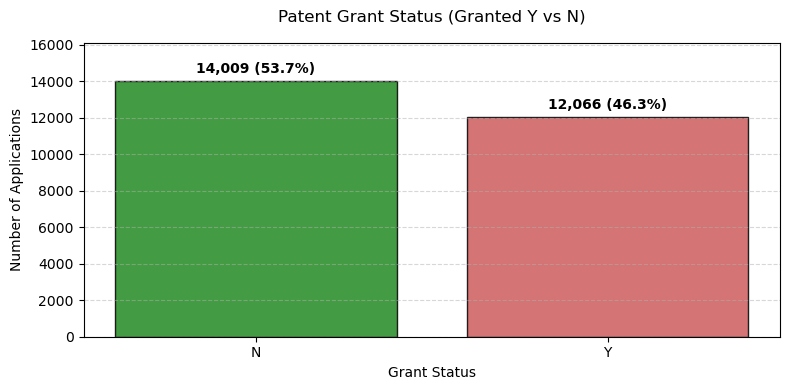

In [7]:
# Query per estrarre lo stato di concessione (granted) di tutte le application del settore
granted_query = (
    db.query(
        TLS201_APPLN.granted,
        func.count(TLS201_APPLN.appln_id).label("count")
    )
    .filter(
        TLS201_APPLN.docdb_family_id.in_(family_ids),
        TLS201_APPLN.ipr_type == IPR_TYPE
    )
    .group_by(TLS201_APPLN.granted)
)

df_granted = patstat.df(granted_query)

# Pulizia e calcolo delle percentuali
df_granted["granted"] = df_granted["granted"].fillna("Unknown / Pending")
total_apps = df_granted["count"].sum()
df_granted["percentage"] = (df_granted["count"] / total_apps) * 100

# Mostriamo la tabella pulita
print("Patent Grant Status Summary:")
print(df_granted.to_string(index=False))

# Grafico a barre in inglese
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(df_granted["granted"], df_granted["count"], color=["forestgreen", "indianred", "gray"], edgecolor="black", alpha=0.85)

for bar in bars:
    height = bar.get_height()
    pct = (height / total_apps) * 100
    ax.text(bar.get_x() + bar.get_width()/2, height + (total_apps * 0.01), 
            f"{height:,} ({pct:.1f}%)", 
            ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_title("Patent Grant Status (Granted Y vs N)", fontsize=12, pad=15)
ax.set_xlabel("Grant Status", fontsize=10)
ax.set_ylabel("Number of Applications", fontsize=10)
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.set_ylim(0, df_granted["count"].max() * 1.15)

plt.tight_layout()
plt.show()

Volume per year

,Quantum Computing,all patents,share (%)
year,,,
2010,97,1156216,0.008389
2011,110,1263098,0.008709
2012,104,1405208,0.007401
2013,123,1559393,0.007888
2014,139,1621467,0.008572
2015,204,1774528,0.011496
2016,303,1976286,0.015332
2017,401,2190307,0.018308
2018,677,2329280,0.029065


Crescita 2010-2023:  Quantum Computing +2730.9%  |  all patents +115.4%


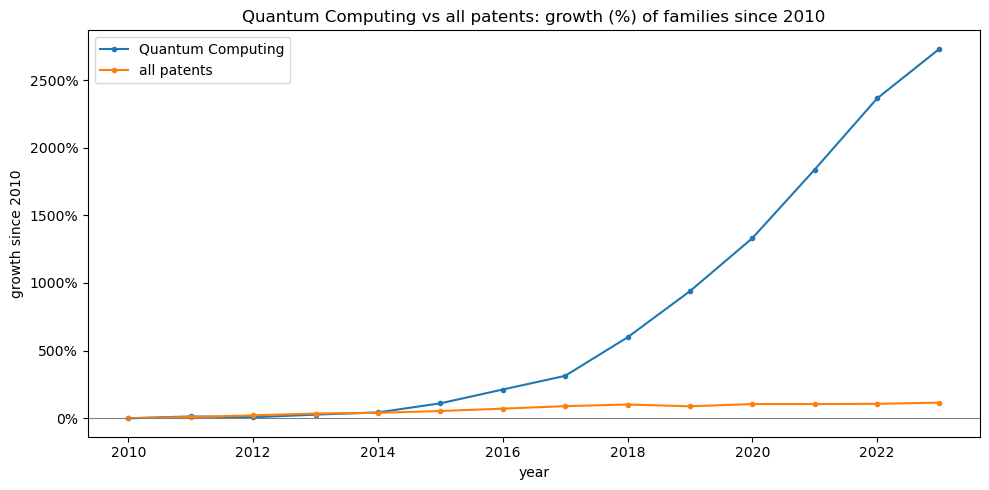

In [10]:
# Family per anno: Quantum Computing vs tutte le family di PATSTAT
from matplotlib.ticker import PercentFormatter

LAST_COMPLETE_YEAR = 2023  # gli ultimi anni in PATSTAT sono incompleti: esclusi dalla crescita

def families_per_year(only_sector):
    # anno della family = earliest_filing_year minimo tra le sue application
    fam = db.query(
        TLS201_APPLN.docdb_family_id.label("fid"),
        func.min(TLS201_APPLN.earliest_filing_year).label("year"),
    ).filter(TLS201_APPLN.ipr_type == IPR_TYPE, TLS201_APPLN.docdb_family_id > 0)
    if only_sector:
        fam = fam.filter(TLS201_APPLN.docdb_family_id.in_(family_ids))
    fam = fam.group_by(TLS201_APPLN.docdb_family_id).subquery()

    q = (db.query(fam.c.year, func.count().label("n"))
         .filter(fam.c.year.between(START_YEAR, END_YEAR))
         .group_by(fam.c.year))
    return patstat.df(q).set_index("year")["n"]

yearly = pd.DataFrame({
    SECTOR_NAME: families_per_year(True),
    "all patents": families_per_year(False),
}).sort_index()
yearly["share (%)"] = yearly[SECTOR_NAME] / yearly["all patents"] * 100
display(yearly)

# Crescita (%) di ogni anno rispetto al primo anno
start, end = START_YEAR, LAST_COMPLETE_YEAR
cols = [SECTOR_NAME, "all patents"]
growth = (yearly.loc[start:end, cols] / yearly.loc[start, cols] - 1) * 100
print(f"Crescita {start}-{end}:  {SECTOR_NAME} {growth.loc[end, SECTOR_NAME]:+.1f}%  |  "
      f"all patents {growth.loc[end, 'all patents']:+.1f}%")

fig, ax = plt.subplots(figsize=(10, 5))
for c in cols:
    ax.plot(growth.index, growth[c], marker="o", ms=3, label=c)
ax.axhline(0, color="grey", lw=0.8)
ax.set(title=f"{SECTOR_NAME} vs all patents: growth (%) of families since {start}",
       xlabel="year", ylabel=f"growth since {start}")
ax.yaxis.set_major_formatter(PercentFormatter(100))
ax.legend()
plt.tight_layout()
plt.show()

vediamo netta crescita maggiore nel settore rispetto a tutti i brevetti.

Soprattuto dal 2014

anche 2023 pur non avendo finito il ciclo di brevetti vediamo che sale meno rapidamente ma sale ancora molto --> settore molto in crescita 

fare un commento sulle % assolute per capire se sono tanti i brevetti di questo settore rispetto al totale oppure no 

MIX TECNOLOGICO 

,families 2010-2023 (frac.),share 2010 (%),share 2023 (%),Δ share (p.p.)
subclass,,,,
G06N,4714.9,11.1,53.8,42.8
Y02D,256.2,0.0,3.7,3.7
G06F,1201.5,4.7,8.3,3.7
H04L,747.6,4.0,5.4,1.4
H04B,212.3,3.0,1.4,-1.6
H10N,645.4,7.2,5.1,-2.1
H10D,210.4,9.3,0.9,-8.3
Other,2355.7,35.4,18.3,-17.1
B82Y,559.2,25.5,3.1,-22.4


,fastest growing subclass,increase vs previous year (families)
year,,
2011,B82Y,4.9
2012,H10N,3.3
2013,G06N,15.9
2014,H04L,3.1
2015,H10N,17.3
2016,B82Y,24.4
2017,G06N,32.1
2018,G06N,71.5
2019,G06N,135.6


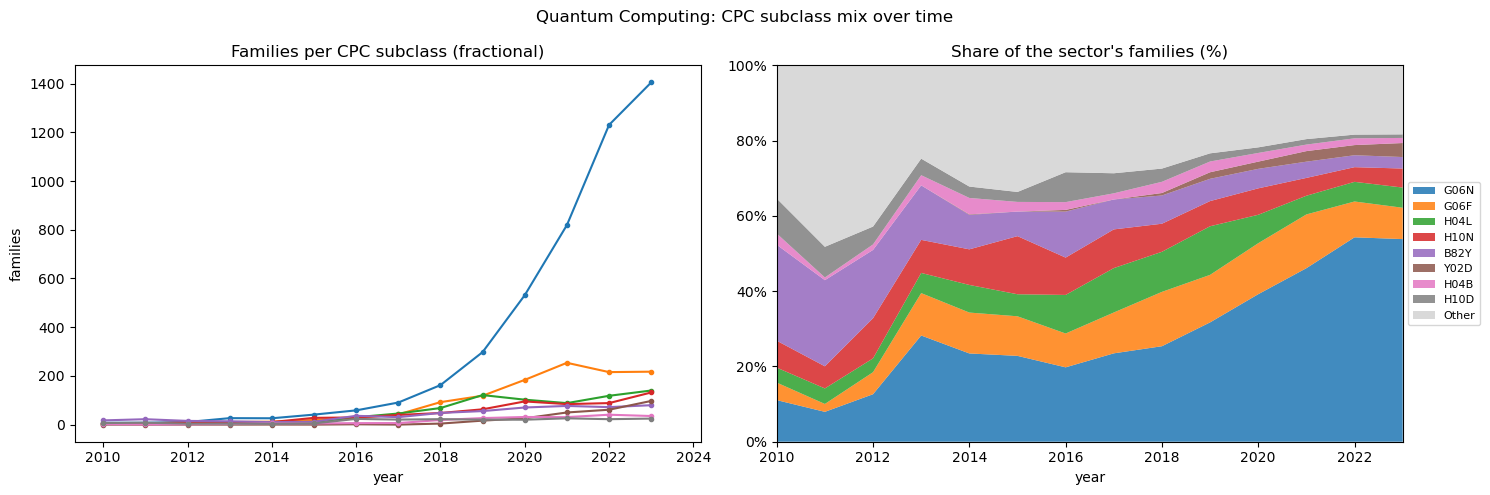

In [12]:
# Mix tecnologico: family del settore per sottoclasse CPC (4 caratteri) e anno, conteggio frazionario
from matplotlib.ticker import PercentFormatter

TOP_N = 8                  # sottoclassi mostrate; le altre finiscono in "Other"
LAST_COMPLETE_YEAR = 2023  # anni successivi incompleti (in grigio nei grafici)

subclass = func.substr(func.replace(TLS224_APPLN_CPC.cpc_class_symbol, " ", ""), 1, 4)

# 1) anno di ogni family = earliest_filing_year minimo
fam = (db.query(TLS201_APPLN.docdb_family_id.label("fid"),
                func.min(TLS201_APPLN.earliest_filing_year).label("year"))
       .filter(TLS201_APPLN.docdb_family_id.in_(family_ids), TLS201_APPLN.ipr_type == IPR_TYPE)
       .group_by(TLS201_APPLN.docdb_family_id).subquery())

# 2) coppie distinte (family, sottoclasse) su tutte le application della family
pairs = (db.query(fam.c.fid, fam.c.year, subclass.label("subclass"))
         .select_from(fam)
         .join(TLS201_APPLN, TLS201_APPLN.docdb_family_id == fam.c.fid)
         .join(TLS224_APPLN_CPC, TLS224_APPLN_CPC.appln_id == TLS201_APPLN.appln_id)
         .filter(TLS201_APPLN.ipr_type == IPR_TYPE)
         .distinct().subquery())

# 3) conteggio frazionario: una family in k sottoclassi dà 1/k a ciascuna
k = db.query(pairs.c.fid, func.count().label("k")).group_by(pairs.c.fid).subquery()
q = (db.query(pairs.c.subclass, pairs.c.year, func.sum(1.0 / k.c.k).label("n_frac"))
     .join(k, k.c.fid == pairs.c.fid)
     .group_by(pairs.c.subclass, pairs.c.year))
cpc = patstat.df(q)
cpc = cpc[cpc["year"].between(START_YEAR, END_YEAR)]

# 4) tabella anno x sottoclasse (top N + Other) e quote percentuali
wide = cpc.pivot_table(index="year", columns="subclass", values="n_frac", aggfunc="sum", fill_value=0)
top = wide.loc[:LAST_COMPLETE_YEAR].sum().nlargest(TOP_N).index
wide = wide[top].assign(Other=wide.drop(columns=top).sum(axis=1))
shares = wide.div(wide.sum(axis=1), axis=0) * 100

start, end = START_YEAR, LAST_COMPLETE_YEAR

# Tabella 1: peso di ogni sottoclasse e come cambia tra il primo e l'ultimo anno completo
summary = pd.DataFrame({
    f"families {start}-{end} (frac.)": wide.loc[start:end].sum(),
    f"share {start} (%)": shares.loc[start],
    f"share {end} (%)": shares.loc[end],
    "Δ share (p.p.)": shares.loc[end] - shares.loc[start],
}).sort_values("Δ share (p.p.)", ascending=False)
display(summary.round(1))

# Tabella 2: ogni anno, la sottoclasse con l'aumento maggiore di family rispetto all'anno prima
diff = wide[top].diff().loc[start + 1:end]
best = pd.DataFrame({"fastest growing subclass": diff.idxmax(axis=1),
                     "increase vs previous year (families)": diff.max(axis=1).round(1)})
display(best)

# Grafici: family per sottoclasse (sx) e quota sul totale del settore (dx)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
colors = list(plt.get_cmap("tab10").colors[:TOP_N]) + ["lightgrey"]

for c, col in zip(wide.columns[:-1], colors):
    axes[0].plot(wide.index, wide[c], marker="o", ms=3, label=c, color=col)
axes[0].set(title="Families per CPC subclass (fractional)", xlabel="year", ylabel="families")

axes[1].stackplot(shares.index, shares.T.values, labels=shares.columns, colors=colors, alpha=0.85)
axes[1].set(title="Share of the sector's families (%)", xlabel="year",
            ylim=(0, 100), xlim=(START_YEAR, END_YEAR))
axes[1].yaxis.set_major_formatter(PercentFormatter(100))

for ax in axes:
    ax.axvspan(LAST_COMPLETE_YEAR + 0.5, END_YEAR + 0.5, color="grey", alpha=0.15, lw=0)
axes[1].legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8)
fig.suptitle(f"{SECTOR_NAME}: CPC subclass mix over time")
plt.tight_layout()
plt.show()

Tabella 1 

vediamo per ogni sotto-settore quante family ci sono sommate dal 2010 al 2023. Ongi family vale 1 e se ha più di una sottocategoria la metto frazionaria. COnsidero anche il 2023 perchè ci sono veramente tanti brevetti (guarda anche figura 1 come la classe blu anche nel 2023 cresce tanto, mentre la arancio ci sat che decresca perchè l'iter è tanto nulgo e non sono ancora finiti i brevetti) RIMANE SEMPRE IL DUBBIO SE CONTARLI TUTTI O SOLO I GRANTED

Vediamo poi quanto ogni sottocategoria pesava in % nel 2010 e quato pesa in % nel 2023 con il delta di crescita 

Tabella 2 

anno per anno quale è la sottocategoria che cresce di più rispetto all'anno precedente 

Grafico 1 

vedo sia il tren generale di quanto crescono i brevetti anno per anno, sia in quel determinata categoria --> assolutamente la blu

Grafico 2

Guarda soprattutto dal 2014 dove abbiamo visto il boom, vedamo che il tren è che i brevetti del blu vanno a totalizzare il mio settoere. 


METTERE LA DESCRIZIONE DEI CODICI CPC


In [ ]:
WIPO

,share of families (%)
techn_sector,
Electrical engineering,89.6
Instruments,5.3
Chemistry,4.0
Mechanical engineering,1.0
Other fields,0.1
Total,100.0


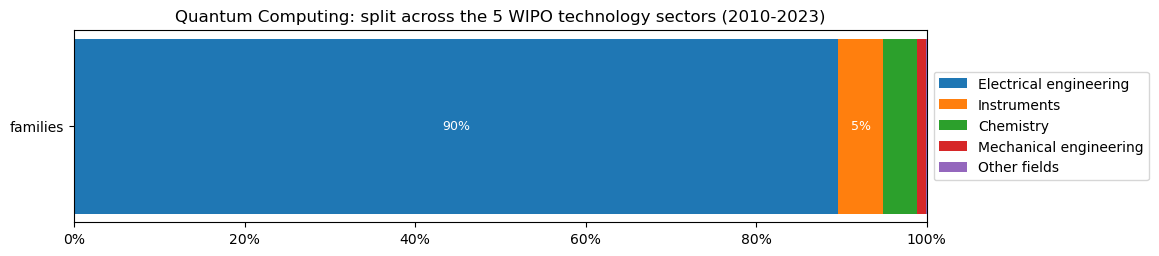

,share of families (%)
techn_field,
Computer technology,60.2
Semiconductors,11.9
Digital communication,8.3
Basic communication processes,3.1
Telecommunications,2.9
Micro-structural and nano-technology,2.8
Optics,2.2
Measurement,2.2
Other,6.5


In [16]:
# WIPO technology fields: quota delle family del settore nei 5 technology sectors e nei 35 fields (conteggio frazionario)
from matplotlib.ticker import PercentFormatter
from epo.tipdata.patstat.database.models import TLS230_APPLN_TECHN_FIELD, TLS901_TECHN_FIELD_IPC

TOP_N = 8
LAST_COMPLETE_YEAR = 2023
T230 = TLS230_APPLN_TECHN_FIELD

# 1) anno di ogni family = earliest_filing_year minimo
fam = (db.query(TLS201_APPLN.docdb_family_id.label("fid"),
                func.min(TLS201_APPLN.earliest_filing_year).label("year"))
       .filter(TLS201_APPLN.docdb_family_id.in_(family_ids), TLS201_APPLN.ipr_type == IPR_TYPE)
       .group_by(TLS201_APPLN.docdb_family_id).subquery())

# 2) peso di ogni field in ogni family (somma dei weight di tls230 sulle sue application)
ff = (db.query(fam.c.fid, T230.techn_field_nr, func.sum(T230.weight).label("w"))
      .select_from(fam)
      .join(TLS201_APPLN, TLS201_APPLN.docdb_family_id == fam.c.fid)
      .join(T230, T230.appln_id == TLS201_APPLN.appln_id)
      .filter(TLS201_APPLN.ipr_type == IPR_TYPE,
              fam.c.year.between(START_YEAR, LAST_COMPLETE_YEAR))
      .group_by(fam.c.fid, T230.techn_field_nr).subquery())

# 3) riscalatura: i pesi di ogni family sommano a 1
tot = db.query(ff.c.fid, func.sum(ff.c.w).label("wt")).group_by(ff.c.fid).subquery()
q = (db.query(ff.c.techn_field_nr, func.sum(ff.c.w / tot.c.wt).label("n_frac"))
     .join(tot, tot.c.fid == ff.c.fid)
     .group_by(ff.c.techn_field_nr))

# nomi dei 35 fields e dei 5 sectors
names = patstat.df(db.query(TLS901_TECHN_FIELD_IPC.techn_field_nr, TLS901_TECHN_FIELD_IPC.techn_field,
                            TLS901_TECHN_FIELD_IPC.techn_sector).distinct()).drop_duplicates("techn_field_nr")
names[["techn_field", "techn_sector"]] = names[["techn_field", "techn_sector"]].apply(lambda s: s.str.strip())

fields = patstat.df(q).merge(names, on="techn_field_nr", how="left")

def share_table(counts):
    """Conteggi -> % (somma 100), 'Other' in fondo e riga 'Total'."""
    shares = (counts / counts.sum() * 100).sort_values(ascending=False)
    order = [i for i in shares.index if i != "Other"] + (["Other"] if "Other" in shares.index else [])
    shares = shares.loc[order].to_frame("share of families (%)")
    shares.loc["Total"] = shares.sum()
    return shares.round(1)

# Tabella 1: 5 technology sectors
sector_shares = share_table(fields.groupby("techn_sector")["n_frac"].sum())
display(sector_shares)

# Grafico: una barra divisa nei 5 sectors (= 100%)
bars = sector_shares.drop("Total")["share of families (%)"]
fig, ax = plt.subplots(figsize=(11, 2.5))
left = 0
for techn_sector, v in bars.items():
    ax.barh(["families"], [v], left=left, label=techn_sector)
    if v >= 5:
        ax.text(left + v / 2, 0, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=9)
    left += v
ax.set(title=f"{SECTOR_NAME}: split across the 5 WIPO technology sectors ({START_YEAR}-{LAST_COMPLETE_YEAR})",
       xlim=(0, 100))
ax.xaxis.set_major_formatter(PercentFormatter(100))
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.show()

# Tabella 2: i 35 technology fields (primi TOP_N, il resto in "Other")
field_counts = fields.groupby("techn_field")["n_frac"].sum()
top_fields = field_counts.nlargest(TOP_N).index
field_counts = field_counts.groupby(field_counts.index.where(field_counts.index.isin(top_fields), "Other")).sum()
display(share_table(field_counts))

Visto che applicans e family avevavno la stessa divisone % sulle categorie wipo considero solo family. Ongi applicans ha una frazine per ogni tecnologia wipo, per la family si sommano tutte e si divide per il totale così ogni family vale sempre tutto 1 diviso fra le varie categorie. 

netta prevalenza di electical egeneering e si computer tecnology + conductor, ci sta

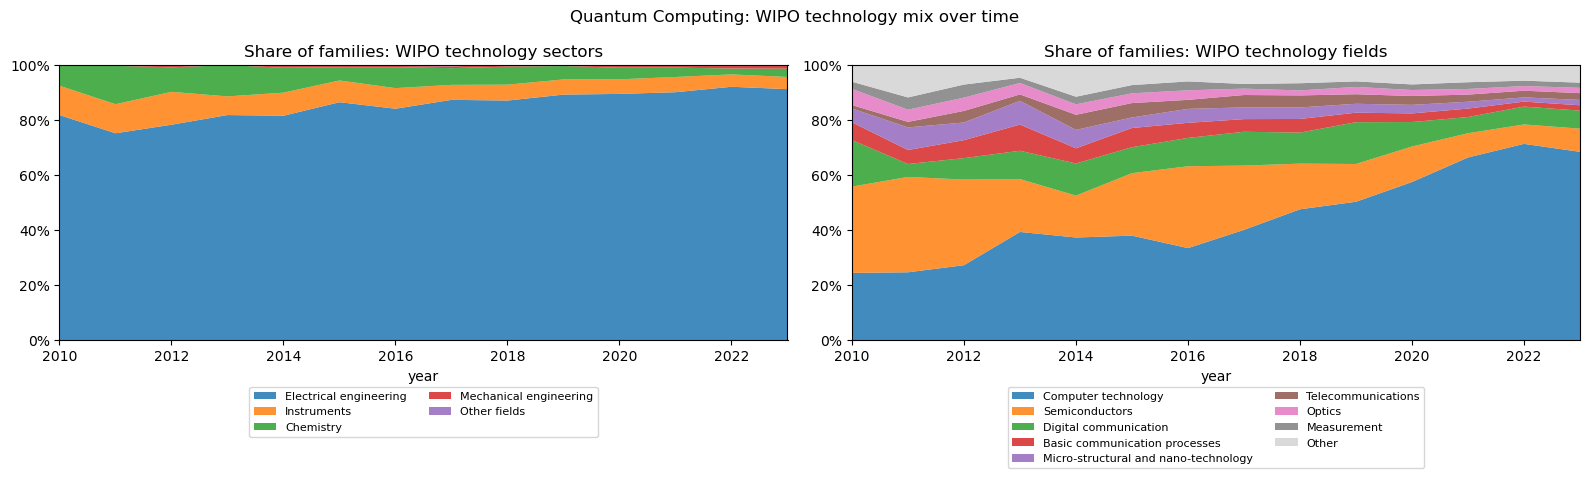

In [18]:
# WIPO: quote delle family per technology sector e per field, anno per anno
yearly_q = (db.query(fam.c.year, ff.c.techn_field_nr, func.sum(ff.c.w / tot.c.wt).label("n_frac"))
            .select_from(ff)
            .join(tot, tot.c.fid == ff.c.fid)
            .join(fam, fam.c.fid == ff.c.fid)
            .group_by(fam.c.year, ff.c.techn_field_nr))
fields_y = patstat.df(yearly_q).merge(names, on="techn_field_nr", how="left")

# field fuori dai primi TOP_N -> "Other"
fields_y["field"] = fields_y["techn_field"].where(fields_y["techn_field"].isin(top_fields), "Other")

# Grafici: area impilata al 100% (sx: 5 sectors, dx: primi TOP_N fields + Other)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, shares, title in zip(axes, (sector_y, field_y), ("WIPO technology sectors", "WIPO technology fields")):
    colors = [ "lightgrey" if c == "Other" else plt.get_cmap("tab10").colors[i] for i, c in enumerate(shares.columns)]
    ax.stackplot(shares.index, shares.T.values, labels=shares.columns, colors=colors, alpha=0.85)
    ax.set(title=f"Share of families: {title}", xlabel="year",
           xlim=(START_YEAR, LAST_COMPLETE_YEAR), ylim=(0, 100))
    ax.yaxis.set_major_formatter(PercentFormatter(100))
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, fontsize=8)
fig.suptitle(f"{SECTOR_NAME}: WIPO technology mix over time")
plt.tight_layout()
plt.show()

vediamo che wipo classic elettrical è costante sempre la prima

per quelle più specifica computer tecnology sale tanto e smiconductor scende un pelo 

GEOGRAFIA 

Quota delle application del settore depositate presso gli IP5: 73.7%


,applications,share (%)
office,,
EP,2653.0,11.0
US,6400.0,26.6
CN,5844.0,24.3
JP,1945.0,8.1
KR,919.0,3.8
WO,3302.0,13.7
Other,3031.0,12.6
Total,24094.0,100.0


Application con paese applicant noto: 66.5%
Application con paese inventor noto: 60.2%


role,applicant share (%),inventor share (%)
ctry,,
US,53.2,50.5
JP,6.1,6.6
CN,5.3,5.4
DE,4.7,4.8
CA,4.6,5.0
Other,26.0,27.7
Total,100.0,100.0


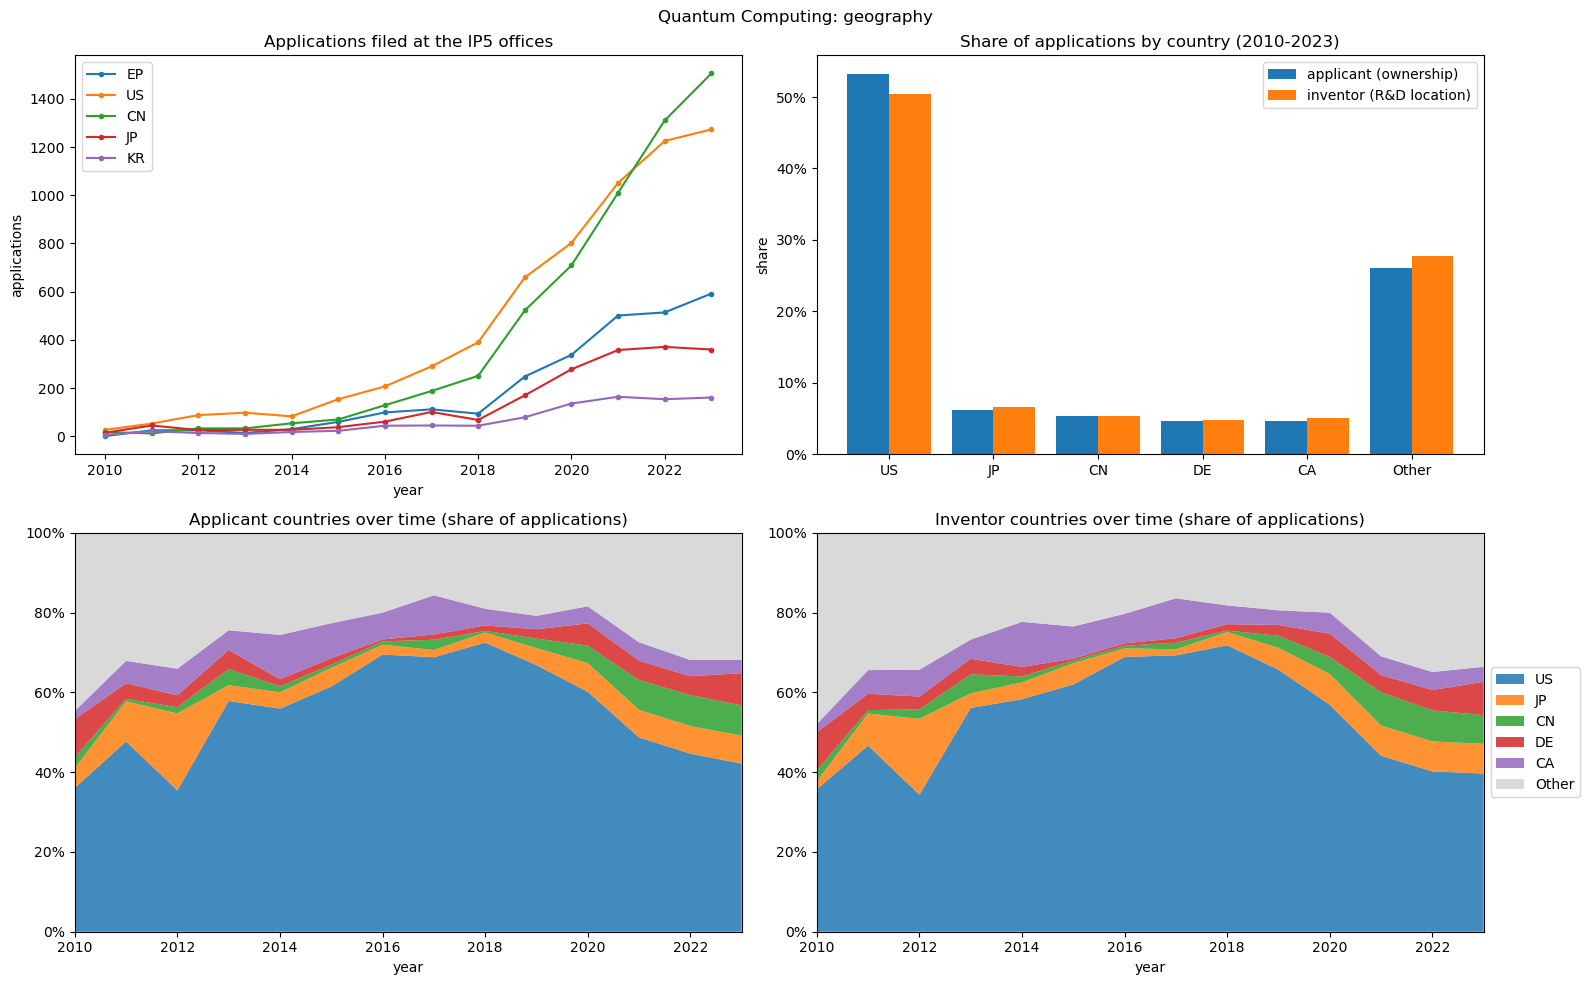

In [21]:
# Geografia (livello application): uffici IP5 + paesi di applicant e inventor (conteggio frazionario)
from matplotlib.ticker import PercentFormatter
from epo.tipdata.patstat.database.models import TLS206_PERSON, TLS207_PERS_APPLN

IP5_OFFICES = ("EP", "US", "CN", "JP", "KR")
TOP_N_CTRY = 5
LAST_COMPLETE_YEAR = 2023

apps = [TLS201_APPLN.docdb_family_id.in_(family_ids),
        TLS201_APPLN.ipr_type == IPR_TYPE,
        TLS201_APPLN.appln_filing_year.between(START_YEAR, LAST_COMPLETE_YEAR)]

# ------------------------------------------------ A) uffici di deposito
off = patstat.df(
    db.query(TLS201_APPLN.appln_auth.label("office"),
             TLS201_APPLN.appln_filing_year.label("year"),
             func.count().label("n"))
    .filter(*apps)
    .group_by(TLS201_APPLN.appln_auth, TLS201_APPLN.appln_filing_year)
)
off["office"] = off["office"].str.strip()
off["office"] = off["office"].where(off["office"].isin(IP5_OFFICES + ("WO",)), "Other")
total_apps = off["n"].sum()

office_tab = off.groupby("office")["n"].sum().reindex(list(IP5_OFFICES) + ["WO", "Other"], fill_value=0).to_frame("applications")
office_tab["share (%)"] = office_tab["applications"] / total_apps * 100
office_tab.loc["Total"] = office_tab.sum()
print(f"Quota delle application del settore depositate presso gli IP5: "
      f"{office_tab.loc[list(IP5_OFFICES), 'share (%)'].sum():.1f}%")
display(office_tab.round(1))

# ------------------------------------------------ B) paesi di applicant e inventor
def country_by_role(role):
    """Ogni application è divisa tra le sue persone distinte con paese noto (somma 1)."""
    seq = TLS207_PERS_APPLN.applt_seq_nr if role == "applicant" else TLS207_PERS_APPLN.invt_seq_nr
    ctry = func.trim(TLS206_PERSON.person_ctry_code)
    persons = (db.query(TLS201_APPLN.appln_id.label("aid"),
                        TLS201_APPLN.appln_filing_year.label("year"),
                        TLS207_PERS_APPLN.person_id, ctry.label("ctry"))
               .join(TLS207_PERS_APPLN, TLS207_PERS_APPLN.appln_id == TLS201_APPLN.appln_id)
               .join(TLS206_PERSON, TLS206_PERSON.person_id == TLS207_PERS_APPLN.person_id)
               .filter(*apps, seq > 0, ctry.isnot(None), ctry != "")
               .distinct().subquery())
    k = db.query(persons.c.aid, func.count().label("k")).group_by(persons.c.aid).subquery()
    q = (db.query(persons.c.ctry, persons.c.year, func.sum(1.0 / k.c.k).label("n_frac"))
         .join(k, k.c.aid == persons.c.aid)
         .group_by(persons.c.ctry, persons.c.year))
    return patstat.df(q).assign(role=role)

countries = pd.concat([country_by_role("applicant"), country_by_role("inventor")], ignore_index=True)

# copertura: application con almeno un paese noto (le altre sono escluse)
for role in ("applicant", "inventor"):
    cov = countries.query("role == @role")["n_frac"].sum() / total_apps * 100
    print(f"Application con paese {role} noto: {cov:.1f}%")

cc = countries.pivot_table(index="ctry", columns="role", values="n_frac", aggfunc="sum", fill_value=0)[["applicant", "inventor"]]
top_ctry = list(cc["applicant"].nlargest(TOP_N_CTRY).index)
cc = cc.groupby(cc.index.where(cc.index.isin(top_ctry), "Other")).sum().reindex(top_ctry + ["Other"], fill_value=0)
ctry_shares = cc / cc.sum() * 100
ctry_shares.loc["Total"] = ctry_shares.sum()
display(ctry_shares.round(1).rename(columns={"applicant": "applicant share (%)", "inventor": "inventor share (%)"}))

# ------------------------------------------------ Grafici
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# (1) application per anno presso ciascun ufficio IP5
off_y = off.pivot_table(index="year", columns="office", values="n", aggfunc="sum", fill_value=0)
for o in IP5_OFFICES:
    if o in off_y.columns:
        axes[0, 0].plot(off_y.index, off_y[o], marker="o", ms=3, label=o)
axes[0, 0].set(title="Applications filed at the IP5 offices", xlabel="year", ylabel="applications")
axes[0, 0].legend()

# (2) applicant vs inventor: quota per paese
plot = ctry_shares.drop("Total")
x = np.arange(len(plot))
axes[0, 1].bar(x - 0.2, plot["applicant"], 0.4, label="applicant (ownership)")
axes[0, 1].bar(x + 0.2, plot["inventor"], 0.4, label="inventor (R&D location)")
axes[0, 1].set_xticks(x, plot.index)
axes[0, 1].set(title=f"Share of applications by country ({START_YEAR}-{LAST_COMPLETE_YEAR})", ylabel="share")
axes[0, 1].yaxis.set_major_formatter(PercentFormatter(100))
axes[0, 1].legend()

# (3)-(4) evoluzione nel tempo delle quote per paese (applicant e inventor)
countries["ctry_p"] = countries["ctry"].where(countries["ctry"].isin(top_ctry), "Other")
colors = list(plt.get_cmap("tab10").colors[:TOP_N_CTRY]) + ["lightgrey"]
for ax, role in zip(axes[1], ("applicant", "inventor")):
    w = (countries.query("role == @role")
         .pivot_table(index="year", columns="ctry_p", values="n_frac", aggfunc="sum", fill_value=0)
         .reindex(columns=top_ctry + ["Other"], fill_value=0))
    w = w.div(w.sum(axis=1), axis=0) * 100
    ax.stackplot(w.index, w.T.values, labels=w.columns, colors=colors, alpha=0.85)
    ax.set(title=f"{role.capitalize()} countries over time (share of applications)", xlabel="year",
           xlim=(START_YEAR, LAST_COMPLETE_YEAR), ylim=(0, 100))
    ax.yaxis.set_major_formatter(PercentFormatter(100))
axes[1, 1].legend(loc="center left", bbox_to_anchor=(1, 0.5))

fig.suptitle(f"{SECTOR_NAME}: geography")
plt.tight_layout()
plt.show()

Tenere o no il 2023 qui fa tanta differenza, vedi un netto trend di cn che sale dal 2022 al 2023

us e cn sono i maggiori in termini asoluti sia come crescita negli ultimi anni 

la divisione di dove fanno r and d e di dove c'è la sede dell'azienda è abbastanza stabile --> non si fa r and d all'esterno. Ho solo il 60% dei patent con questi dati ma è per capire il trend, bastano. 

Gli ultimi 2 grafici pr questo sono simili --> tieni solo applicant. Vediamo che us aveva la maggior parte fra 2014 e 2020 circa, poi hannoiniziato a salire jp cn e gli altri. Rimane comunque un merato di ricerca colonizzato da us. 